In [ ]:
from pathlib import Path

import astropy.table as at
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
allstar = at.Table.read("~/data/apogee/dr17/allStarLite-dr17-synspec_rev1.fits")
allvisit = at.Table.read("~/data/apogee/dr17/allVisit-dr17-synspec.fits")
calib_verr = at.Table.read(
    "~/projects/apogee-dr17-binaries/vac-pipeline/cache/allVisit-dr17-synspec-calib-verr.fits"
)
calib_verr["CALIB_VERR"] = np.sqrt(0.15**2 + calib_verr["CALIB_VERR"] ** 2)

# Stellar parameter cuts:

In [3]:
keep_stars = (
    (allstar["LOGG"] > 3)
    & (allstar["LOGG"] < 3.5)
    & (allstar["TEFF"] < 5200.0)
    & (allstar["TEFF"] > 4700.0)
    & (allstar["SNR"] > 20)
    & (allstar["RV_FLAG"] == 0)
    & (allstar["N_COMPONENTS"] == 1)
    & (allstar["NVISITS"] >= 3)
)
allstar = allstar[keep_stars]

In [4]:
# plt.hist2d(
#     allstar["TEFF"],
#     allstar["LOGG"],
#     bins=(np.linspace(3200, 6400, 128), np.linspace(0, 5, 128)),
#     cmap="Greys",
#     norm=mpl.colors.LogNorm(),
# )
# plt.xlim(6400, 3200)
# plt.ylim(5.5, 0)

## Quality cuts:

In [5]:
# Remove bad velocities / NaN / Inf values:
bad_visit_mask = (
    np.isfinite(allvisit["VHELIO"])
    & np.isfinite(allvisit["VRELERR"])
    & (allvisit["VRELERR"] < 100.0)
    & (allvisit["VHELIO"] != -9999)
    & (np.abs(allvisit["VHELIO"]) < 500.0)
)
allvisit = allvisit[bad_visit_mask]
allstar = allstar[np.isin(allstar["APOGEE_ID"], allvisit["APOGEE_ID"])]

In [6]:
starflag_bits = np.array(
    [
        3,  # VERY_BRIGHT_NEIGHBOR
        16,  # SUSPECT_RV_COMBINATION
        18,  # BAD_RV_COMBINATION
        19,  # RV_REJECT
        20,  # RV_SUSPECT
        21,  # MULTIPLE_SUSPECT
        22,  # RV_FAIL
    ]
)
starflag_bitmask = np.sum(2**starflag_bits)

star_starflag_mask = (allstar["STARFLAG"] & starflag_bitmask) == 0
visit_starflag_mask = (allvisit["STARFLAG"] & starflag_bitmask) == 0

In [7]:
rvflag_bits = np.array(
    [
        1,  # RV_BCFIT_FAIL
        3,  # RV_WINDOW_MASK
        4,  # RV_VALUE_ERROR
        5,  # RV_RUNTIME_ERROR
        6,  # RV_ERROR
        8,  # NO_GOOD_VISITS
        9,  # ALL_VISITS_REJECTED
        10,  # RV_REJECT
        11,  # RV_SUSPECT
    ]
)
rvflag_bitmask = np.sum(2**rvflag_bits)
rvflag_mask = (allvisit["RV_FLAG"] & rvflag_bitmask) == 0

# After quality and bitmask cut, figure out what APOGEE_IDs remain
allvisit = allvisit[visit_starflag_mask & rvflag_mask]
v_apogee_ids, counts = np.unique(allvisit["APOGEE_ID"], return_counts=True)
allstar_visit_mask = np.isin(allstar["APOGEE_ID"], v_apogee_ids[counts >= 3])

In [8]:
allstar = allstar[allstar_visit_mask & star_starflag_mask]

# Only load visits for stars that we're loading
allvisit = allvisit[np.isin(allvisit["APOGEE_ID"], allstar["APOGEE_ID"])]
v_apogee_ids2 = np.unique(allvisit["APOGEE_ID"])
star_mask2 = np.isin(allstar["APOGEE_ID"], v_apogee_ids2)
allstar = allstar[star_mask2]

_, idx = np.unique(allstar["APOGEE_ID"], return_index=True)
allstar = allstar[idx]

allvisit = allvisit[np.isin(allvisit["APOGEE_ID"], allstar["APOGEE_ID"])]
allvisit = at.join(allvisit, calib_verr, keys="VISIT_ID")

In [9]:
v_apogee_ids, counts = np.unique(allvisit["APOGEE_ID"], return_counts=True)

In [10]:
count_masks = [counts == 3, counts == 6, (counts >= 12) & (counts < 20)]

In [11]:
def estimate_jitter(y, sigma, mu=None, n_iter=2):
    if mu is None:
        mu = np.sum(y / sigma**2) / np.sum(1.0 / sigma**2)
    d = (np.asarray(y) - mu) ** 2 - np.asarray(sigma) ** 2
    var = np.asarray(sigma) ** 2
    t = np.maximum(d.mean(-1, keepdims=True), 0.0)
    for _ in range(n_iter):
        w = 1.0 / (t + var) ** 2
        t = np.maximum((w * d).sum(-1, keepdims=True) / w.sum(-1, keepdims=True), 0.0)
    return np.sqrt(t[..., 0])

In [14]:
rng = np.random.default_rng(seed=42)
star_ids = []
for i, count_mask in enumerate(count_masks):
    print(count_mask.sum())
    _ids = v_apogee_ids[count_mask]
    _stars = allstar[np.isin(allstar["APOGEE_ID"], _ids)]
    idx = np.arange(len(_stars))
    rng.shuffle(idx)

    status = {"v>20": False, "v<1": False}
    for star in _stars[idx[:1000]]:
        _visits = allvisit[allvisit["APOGEE_ID"] == star["APOGEE_ID"]]

        vscatter = estimate_jitter(_visits["VHELIO"], _visits["CALIB_VERR"])
        if vscatter > 20.0 and vscatter < 50.0:
            status["v>20"] = star["APOGEE_ID"]
        if vscatter < 0.5 and vscatter > 0.2:
            status["v<1"] = star["APOGEE_ID"]

        if status["v>20"] and status["v<1"]:
            break
    star_ids.append(status)

10956
3436
1010


In [28]:
data_path = Path("..").resolve() / "data" / "apogee"
data_path.mkdir(exist_ok=True)

for counts_bin, sid in enumerate(star_ids):
    for _name, apid in sid.items():
        scatter_bin = 0 if ">" in _name else 1
        filename = data_path / f"counts{counts_bin}_scatter{scatter_bin}.ecsv"

        visits = allvisit[allvisit["APOGEE_ID"] == apid]
        data = at.Table(
            {
                "jd": np.array(visits["JD"]),
                "rv": np.array(visits["VHELIO"]),
                "rv_err": np.array(visits["CALIB_VERR"]),
            }
        )
        data.meta["APOGEE_ID"] = apid
        data.write(filename, format="ascii.ecsv")

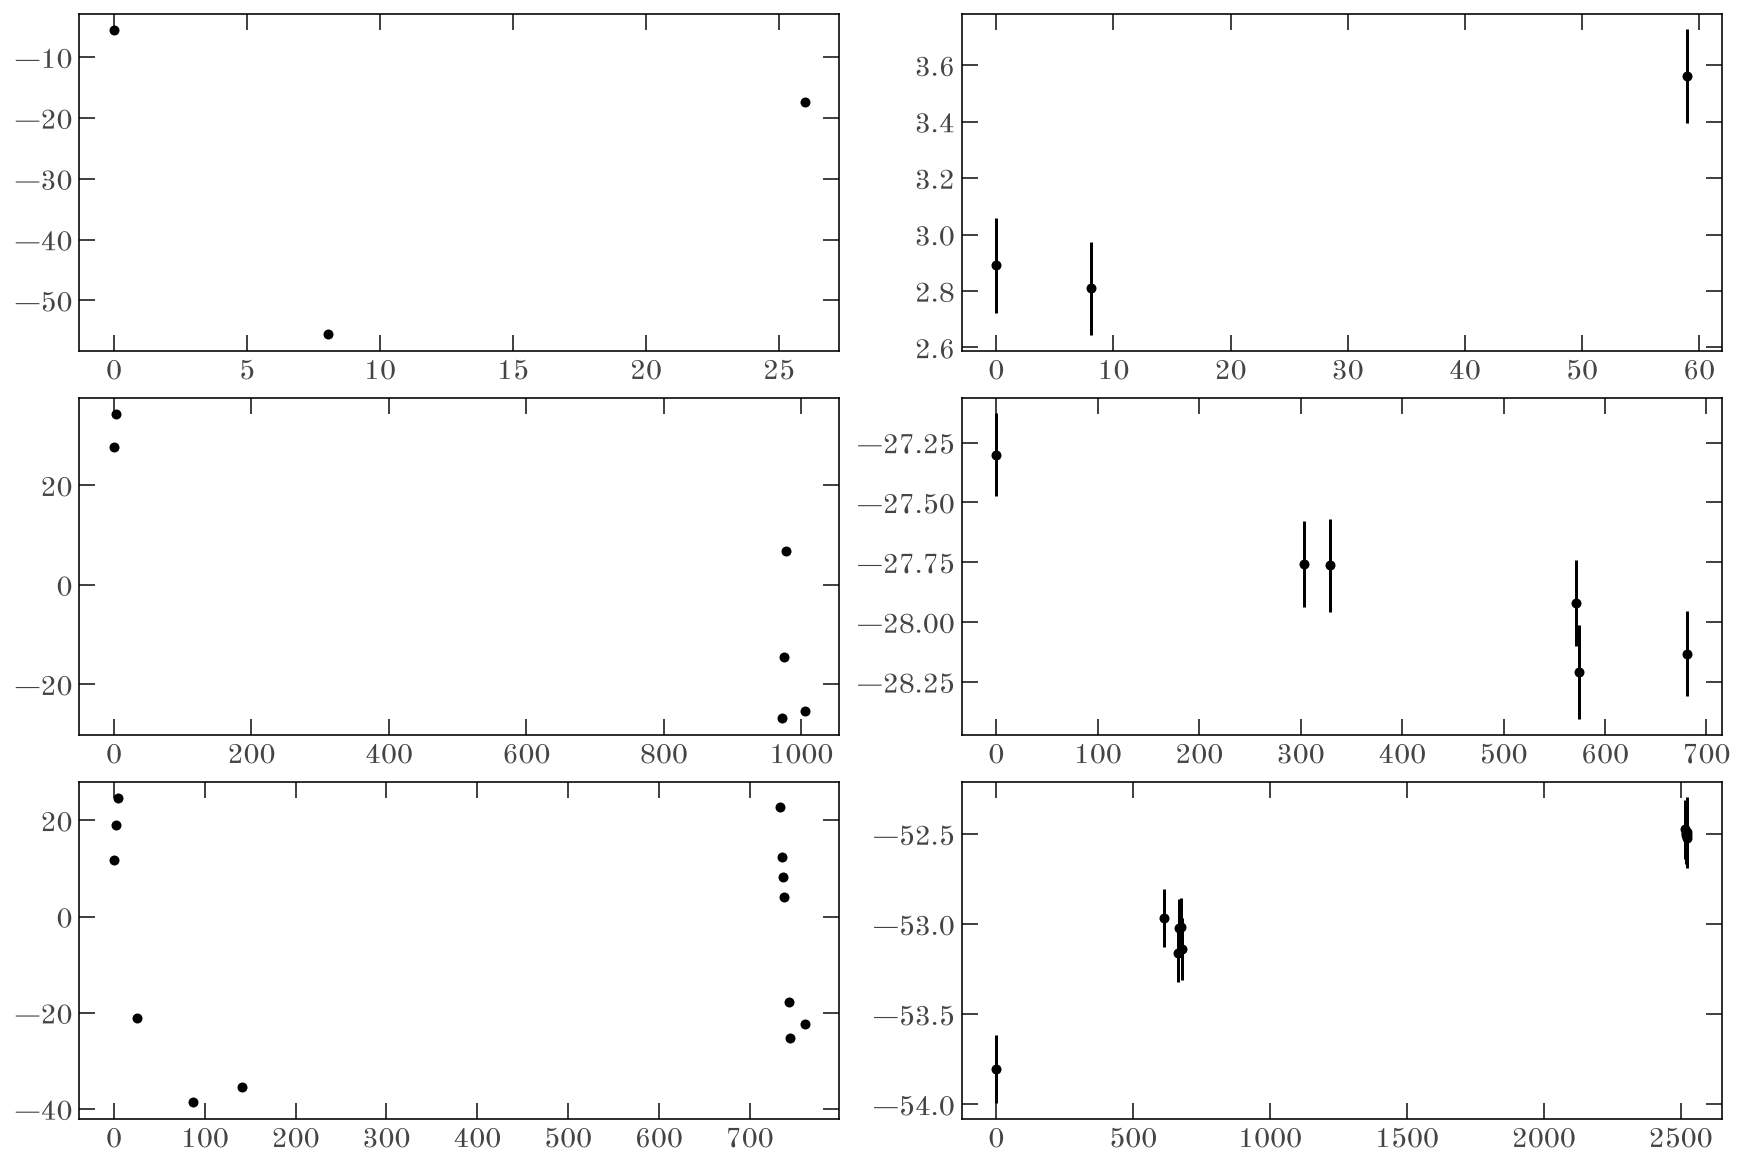

In [29]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8))

i = 0
for sid in star_ids:
    for k, v in sid.items():
        visits = allvisit[allvisit["APOGEE_ID"] == v]

        ax = axes.flat[i]
        ax.errorbar(
            visits["JD"] - visits["JD"].min(),
            visits["VHELIO"],
            yerr=visits["CALIB_VERR"],
            fmt="o",
            color="C0",
        )
        i += 1